# Inventory Demand Forecasting

Built with AI assistance. The sales data is simulated because no real store file was available. Run the cells top to bottom. Everything except `data/sales_raw.csv` is created by this notebook.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

os.makedirs("data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

LEAD_WEEKS = 2
REVIEW_WEEKS = 1
COVER = LEAD_WEEKS + REVIEW_WEEKS
Z_95 = 1.645
MARGIN = 0.30
CARRY = 0.25

## 1. Load the raw data

In [2]:
raw = pd.read_csv("data/sales_raw.csv")
print(raw.shape)
print(raw.isna().sum())

(4735, 11)
week_start                   0
product_id                   0
category                     0
unit_price                  40
promo_flag                   0
holiday_flag                30
units_sold                  30
stockout_flag               30
stock_on_hand_end           30
on_order_before_decision    30
store_order_placed          30
dtype: int64


## 2. Clean the data

In [3]:
df = raw.copy()
df["category"] = df.category.str.strip().str.title()
df["week_start"] = pd.to_datetime(df.week_start, format="mixed")
df["_missing"] = df.isna().sum(axis=1)
df = df.sort_values("_missing").drop_duplicates(["product_id", "week_start"]).drop(columns="_missing")
print("rows after removing duplicates:", len(df))

rows after removing duplicates: 4710


In [4]:
plan = df[df.units_sold.isna()][["product_id", "week_start", "category", "unit_price", "promo_flag", "holiday_flag"]].copy()
df = df[df.units_sold.notna()].copy()
print("next-week plan rows set aside:", len(plan))

print("negative sales fixed:", (df.units_sold < 0).sum())
df["units_sold"] = df.units_sold.abs().astype(int)

base_guess = df.dropna(subset=["unit_price"]).assign(b=lambda d: d.unit_price / np.where(d.promo_flag == 1, 0.8, 1))
base_price = base_guess.groupby("product_id").b.median().round(0)
print("missing prices filled:", df.unit_price.isna().sum())
df["unit_price"] = df.unit_price.fillna(df.product_id.map(base_price) * np.where(df.promo_flag == 1, 0.8, 1)).round(2)

df["holiday_flag"] = pd.to_datetime(df.week_start).dt.isocalendar().week.astype(int).isin([2, 43, 44]).astype(int)
df = df.sort_values(["product_id", "week_start"]).reset_index(drop=True)

next-week plan rows set aside: 30
negative sales fixed: 12
missing prices filled: 40


In [5]:
assert not df.duplicated(["product_id", "week_start"]).any()
assert df.isna().sum().sum() == 0
assert (df.units_sold >= 0).all()
df["week_start"] = df.week_start.dt.strftime("%Y-%m-%d")
plan["week_start"] = plan.week_start.dt.strftime("%Y-%m-%d")
df.to_csv("data/sales_clean.csv", index=False)
plan.to_csv("outputs/next_week_plan.csv", index=False)
print("clean data saved:", df.shape)

clean data saved: (4680, 11)


## 3. Look at the data

Simple patterns first: total sales over time, seasonality, promotions, and what happens after a stockout.

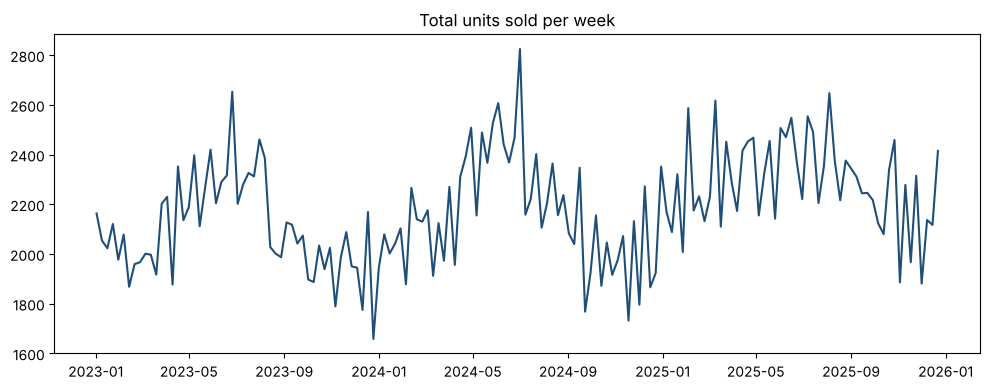

In [6]:
clean = pd.read_csv("data/sales_clean.csv", parse_dates=["week_start"])
weekly = clean.groupby("week_start").units_sold.sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.index, weekly.values, color="#1f4e79")
ax.set_title("Total units sold per week")
fig.tight_layout()
fig.savefig("outputs/figures/01_weekly_total.png", dpi=150)
plt.show()

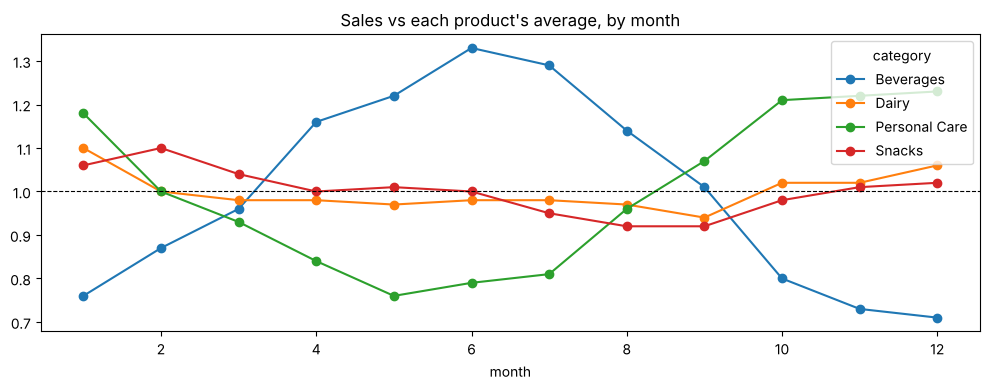

In [7]:
clean["month"] = clean.week_start.dt.month
clean["vs_own_average"] = clean.units_sold / clean.groupby("product_id").units_sold.transform("mean")
season = clean.groupby(["category", "month"]).vs_own_average.mean().unstack(0).round(2)
season.to_csv("outputs/seasonality_by_month.csv")
fig, ax = plt.subplots(figsize=(10, 4))
season.plot(ax=ax, marker="o")
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.set_title("Sales vs each product's average, by month")
fig.tight_layout()
fig.savefig("outputs/figures/02_seasonality.png", dpi=150)
plt.show()

In [8]:
promo = clean.groupby(["product_id", "promo_flag"]).units_sold.mean().unstack()
promo_lift = (promo[1] / promo[0]).round(2)
promo_lift.to_csv("outputs/promo_lift.csv")
print("median promo lift:", promo_lift.median())
print("share of product-weeks out of stock:", round(clean.stockout_flag.mean(), 3))
after = clean.assign(next_week=clean.groupby("product_id").units_sold.shift(-1)).dropna(subset=["next_week"])
print("average units sold the week after:")
print(after.groupby("stockout_flag").next_week.mean().round(1))

median promo lift: 1.35
share of product-weeks out of stock: 0.3
average units sold the week after:
stockout_flag
0.0    74.0
1.0    70.0
Name: next_week, dtype: float64


## 4. Build the inputs for the model

For each product and week, the inputs are what we know before that week starts. The target is next week's sales.

In [9]:
plan = pd.read_csv("outputs/next_week_plan.csv", parse_dates=["week_start"])
clean["is_plan"] = 0
plan["is_plan"] = 1
both = pd.concat([clean, plan], ignore_index=True).sort_values(["product_id", "week_start"]).reset_index(drop=True)
both["week_of_year"] = both.week_start.dt.isocalendar().week.astype(int)
both["week_no"] = both.groupby("product_id").cumcount()
base = clean.groupby("product_id").unit_price.max()

g = both.groupby("product_id")
both["lag1"] = both.units_sold
both["lag2"] = g.units_sold.shift(1)
both["lag3"] = g.units_sold.shift(2)
both["lag4"] = g.units_sold.shift(3)
both["avg4"] = g.units_sold.transform(lambda x: x.rolling(4).mean())
both["avg8"] = g.units_sold.transform(lambda x: x.rolling(8).mean())
both["std4"] = g.units_sold.transform(lambda x: x.rolling(4).std(ddof=0))
both["last_year"] = g.units_sold.shift(51)
both["price_ratio"] = g.unit_price.shift(-1) / both.product_id.map(base)
both["next_promo"] = g.promo_flag.shift(-1)
both["next_holiday"] = g.holiday_flag.shift(-1)
both["sin_week"] = np.sin(2 * np.pi * g.week_of_year.shift(-1) / 52)
both["cos_week"] = np.cos(2 * np.pi * g.week_of_year.shift(-1) / 52)
both["target"] = g.units_sold.shift(-1)
both["next3_total"] = g.units_sold.shift(-1) + g.units_sold.shift(-2) + g.units_sold.shift(-3)

dummies = pd.get_dummies(both.category, prefix="cat", dtype=float)
both = pd.concat([both, dummies], axis=1)
FEATURES = ["lag1", "lag2", "lag3", "lag4", "avg4", "avg8", "std4", "last_year",
            "price_ratio", "next_promo", "next_holiday", "sin_week", "cos_week"] + list(dummies.columns)

In [10]:
origin = both[(both.is_plan == 0) & (both.week_no >= 52)]
train = origin[origin.week_no <= 141]
test = origin[(origin.week_no >= 142) & (origin.week_no <= 154)]
live = origin[origin.week_no == 155].copy()
print("training rows:", len(train), "| test rows:", len(test), "| next-week rows:", len(live))

training rows: 2700 | test rows: 390 | next-week rows: 30


## Feature engineering

Each input is built from information known before the forecast week. The table below lists every input and how strongly it moves with next week's sales in the training weeks. Correlation runs from -1 to 1. Values near zero mean the input carries little linear signal on its own.

In [11]:
feature_notes = {
    "lag1": "This week's sales",
    "lag2": "Sales one week ago",
    "lag3": "Sales two weeks ago",
    "lag4": "Sales three weeks ago",
    "avg4": "Average sales over the last 4 weeks",
    "avg8": "Average sales over the last 8 weeks",
    "std4": "Spread of sales over the last 4 weeks",
    "last_year": "Sales in the same week last year",
    "price_ratio": "Next week's planned price relative to normal",
    "next_promo": "Next week's planned promotion (0 or 1)",
    "next_holiday": "Next week is a festival week (0 or 1)",
    "sin_week": "Week of year, sine part",
    "cos_week": "Week of year, cosine part",
}
feature_table = pd.DataFrame({
    "what_it_is": pd.Series({k: feature_notes.get(k, "Category flag (0 or 1)") for k in FEATURES}),
    "correlation_with_next_week_sales": train[FEATURES].corrwith(train.target).round(3),
})
feature_table.to_csv("outputs/feature_table.csv")
feature_table.sort_values("correlation_with_next_week_sales", ascending=False)

,what_it_is,correlation_with_next_week_sales
avg8,Average sales over the last 8 weeks,0.773
avg4,Average sales over the last 4 weeks,0.763
lag2,Sales one week ago,0.735
lag4,Sales three weeks ago,0.670
last_year,Sales in the same week last year,0.657
lag3,Sales two weeks ago,0.647
cat_Beverages,Category flag (0 or 1),0.525
lag1,This week's sales,0.521
std4,Spread of sales over the last 4 weeks,0.462
next_promo,Next week's planned promotion (0 or 1),0.218


## 5. Baselines and models

Two baselines, then five models: ridge regression, random forest, gradient boosting, LightGBM and XGBoost. Each tree model's settings are tuned on the validation weeks, then the best model is chosen on the same weeks. The test weeks are not used for tuning or choosing.

In [12]:
def make_models():
    return {
        "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=10,
                                               n_jobs=-1, random_state=42),
        "Gradient boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                            max_leaf_nodes=15, min_samples_leaf=20,
                                                            random_state=42),
        "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                  min_child_samples=20, random_state=42, verbose=-1),
        "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                min_child_weight=20, random_state=42),
    }


POLICIES = ["Last week's sales", "4-week average", "Ridge regression", "Random forest",
            "Gradient boosting", "LightGBM", "XGBoost"]
MODELS = ["Ridge regression", "Random forest", "Gradient boosting", "LightGBM", "XGBoost"]


def predict(policy, rows, models):
    if policy == "Last week's sales":
        return pd.Series(rows.lag1.clip(lower=0).to_numpy(), index=rows.index)
    if policy == "4-week average":
        return pd.Series(rows.avg4.to_numpy(), index=rows.index)
    return pd.Series(np.clip(models[policy].predict(rows[FEATURES]), 0, None), index=rows.index)


def error_rate(actual, forecast):
    """Total absolute error divided by total actual sales."""
    return np.abs(actual - forecast).sum() / actual.sum()


def mae(actual, forecast):
    """Average size of a miss, in units."""
    return np.abs(actual - forecast).mean()


def rmse(actual, forecast):
    """Square root of the average squared miss. Big misses count more."""
    return np.sqrt(((actual - forecast) ** 2).mean())


val = train[train.week_no >= 130]
fit_part = train[train.week_no < 130]

## Hyperparameter tuning

Each tree model gets a small set of settings (22 combinations in total). Each combination is trained on weeks 52 to 129 and scored on the validation weeks 130 to 141. The best setting per model is kept. The test weeks are not used here.

In [13]:
from sklearn.model_selection import ParameterGrid


def build_model(name, params):
    if name == "Random forest":
        return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, **params)
    if name == "Gradient boosting":
        return HistGradientBoostingRegressor(max_iter=300, random_state=42, **params)
    if name == "LightGBM":
        return LGBMRegressor(n_estimators=300, min_child_samples=20, random_state=42, verbose=-1, **params)
    return XGBRegressor(n_estimators=300, min_child_weight=20, random_state=42, **params)


GRIDS = {
    "Random forest": {"min_samples_leaf": [5, 10, 20], "max_features": [0.5, 1.0]},
    "Gradient boosting": {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 15, 31]},
    "LightGBM": {"learning_rate": [0.03, 0.1], "num_leaves": [7, 15, 31]},
    "XGBoost": {"learning_rate": [0.03, 0.1], "max_depth": [3, 5]},
}

tuning_rows = []
TUNED = {}
for name, grid in GRIDS.items():
    best_err, best_params = None, None
    for params in ParameterGrid(grid):
        model = build_model(name, params).fit(fit_part[FEATURES], fit_part.target)
        pred = pd.Series(np.clip(model.predict(val[FEATURES]), 0, None), index=val.index)
        err = error_rate(val.target, pred)
        tuning_rows.append({"model": name, **params, "validation_error": round(err, 4)})
        if best_err is None or err < best_err:
            best_err, best_params = err, params
    TUNED[name] = best_params

tuning = pd.DataFrame(tuning_rows)
tuning.to_csv("outputs/tuning_results.csv", index=False)
print("best settings found on validation weeks:")
for name, params in TUNED.items():
    print(" ", name, params)


def make_models():
    models = {"Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0))}
    for name in GRIDS:
        models[name] = build_model(name, TUNED[name])
    return models


val_models = make_models()
for m in val_models.values():
    m.fit(fit_part[FEATURES], fit_part.target)

val_error = {p: error_rate(val.target, predict(p, val, val_models)) for p in POLICIES}
BEST = min(MODELS, key=lambda m: val_error[m])
validation_table = pd.Series(val_error, name="validation_error").sort_values().round(4)
validation_table.to_csv("outputs/validation_comparison.csv")
print(validation_table)
print("chosen model:", BEST)

best settings found on validation weeks:
  Random forest {'max_features': 1.0, 'min_samples_leaf': 10}
  Gradient boosting {'learning_rate': 0.03, 'max_leaf_nodes': 7}
  LightGBM {'learning_rate': 0.03, 'num_leaves': 7}
  XGBoost {'learning_rate': 0.03, 'max_depth': 3}


Random forest        0.2312
Gradient boosting    0.2328
LightGBM             0.2332
XGBoost              0.2337
Ridge regression     0.2549
4-week average       0.2900
Last week's sales    0.4016
Name: validation_error, dtype: float64
chosen model: Random forest


In [14]:
final_models = make_models()
for m in final_models.values():
    m.fit(train[FEATURES], train.target)

SIGMA = {}
for p in POLICIES:
    errors = val.target - predict(p, val, val_models)
    SIGMA[p] = errors.groupby(val.product_id).std()

## 6. Accuracy on the test weeks

In [15]:
actual = test.target
test_forecasts = {p: predict(p, test, final_models) for p in POLICIES}
accuracy = pd.DataFrame({
    "WAPE": {p: error_rate(actual, f) for p, f in test_forecasts.items()},
    "MAE_units": {p: mae(actual, f) for p, f in test_forecasts.items()},
    "RMSE_units": {p: rmse(actual, f) for p, f in test_forecasts.items()},
})
accuracy["better_than_last_week"] = (1 - accuracy.WAPE / accuracy.loc["Last week's sales", "WAPE"]).round(3)
accuracy = accuracy.round(4)
accuracy = accuracy.rename(columns={"WAPE": "error_rate"})
accuracy.to_csv("outputs/accuracy.csv")
accuracy

,error_rate,MAE_units,RMSE_units,better_than_last_week
Last week's sales,0.5048,36.5205,54.5514,0.000
4-week average,0.3483,25.1987,35.9155,0.310
Ridge regression,0.2924,21.1512,30.0679,0.421
Random forest,0.2779,20.1023,28.8702,0.450
Gradient boosting,0.2771,20.0461,28.5824,0.451
LightGBM,0.2791,20.1905,29.1548,0.447
XGBoost,0.2817,20.3788,29.0439,0.442


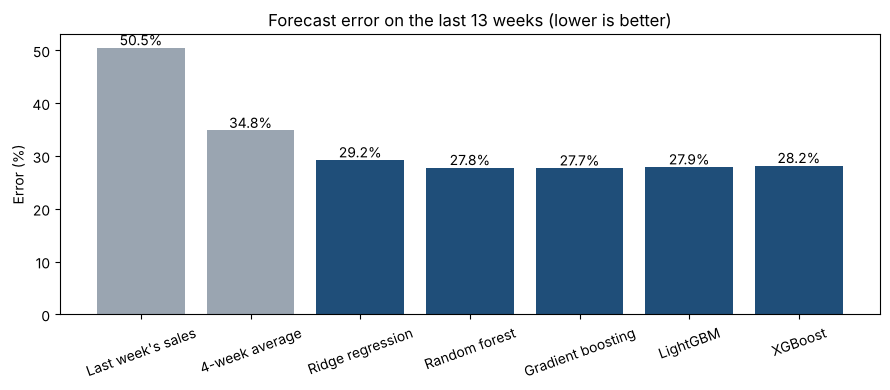

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(accuracy.index, accuracy.error_rate * 100,
       color=["#9aa5b1" if p in ["Last week's sales", "4-week average"] else "#1f4e79" for p in accuracy.index])
ax.tick_params(axis="x", rotation=20)
for i, v in enumerate(accuracy.error_rate * 100):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_ylabel("Error (%)")
ax.set_title("Forecast error on the last 13 weeks (lower is better)")
fig.tight_layout()
fig.savefig("outputs/figures/03_accuracy.png", dpi=150)
plt.show()

## 7. Reorder simulation

Order quantity = 3 weeks of forecast + safety stock − (stock on hand + stock on order), never below zero. Demand here is recorded sales, which understate true demand in stockout weeks.

In [17]:
def order_quantity(rows, forecast, z, policy):
    pos = rows.stock_on_hand_end + rows.on_order_before_decision
    safety = z * rows.product_id.map(SIGMA[policy]) * np.sqrt(COVER)
    return np.maximum(0, COVER * forecast + safety - pos)


def cost_of(rows, qty):
    available = rows.stock_on_hand_end + rows.on_order_before_decision + qty
    short = (rows.next3_total - available).clip(lower=0)
    extra = (available - rows.next3_total).clip(lower=0)
    cost = short * rows.unit_price * MARGIN + extra * rows.unit_price * (1 - MARGIN) * CARRY
    return short, extra, cost


def summarise(z):
    sim = test[test.week_no <= 152]
    options = {"Store's recorded orders": sim.store_order_placed.fillna(0)}
    for p in POLICIES:
        options[p] = order_quantity(sim, predict(p, sim, final_models), z, p)
    rows = []
    for name, qty in options.items():
        short, extra, cost = cost_of(sim, qty)
        rows.append({"policy": name,
                     "units_short": round(short.sum()),
                     "units_extra": round(extra.sum()),
                     "share_of_cycles_short": round((short > 0).mean(), 2),
                     "total_cost_inr": round(cost.sum())})
    return pd.DataFrame(rows).set_index("policy")

In [18]:
Z_OPTIMAL = NormalDist().inv_cdf(MARGIN / (MARGIN + (1 - MARGIN) * CARRY))
cost_95 = summarise(Z_95)
cost_optimal = summarise(Z_OPTIMAL)
cost_95.to_csv("outputs/reorder_cost_95pct.csv")
cost_optimal.to_csv("outputs/reorder_cost_optimal.csv")
print("95% safety stock:")
print(cost_95)
print()
print("cost-optimal safety stock (z =", round(Z_OPTIMAL, 3), "):")
print(cost_optimal)

95% safety stock:
                         units_short  units_extra  share_of_cycles_short  \
policy                                                                     
Store's recorded orders        13223         2843                   0.78   
Last week's sales               1279        40317                   0.11   
4-week average                   396        28651                   0.07   
Ridge regression                1906        24580                   0.18   
Random forest                   1150        23817                   0.13   
Gradient boosting               1088        23314                   0.13   
LightGBM                        1087        23754                   0.13   
XGBoost                         1190        24055                   0.14   

                         total_cost_inr  
policy                                   
Store's recorded orders         1148196  
Last week's sales               1790231  
4-week average                  1227291  
Ridge regre

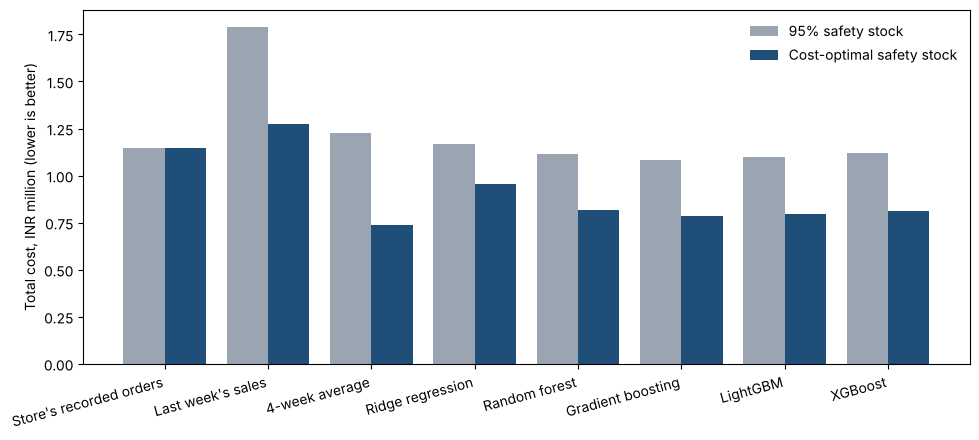

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(cost_95))
ax.bar(x - 0.2, cost_95.total_cost_inr / 1e6, 0.4, color="#9aa5b1", label="95% safety stock")
ax.bar(x + 0.2, cost_optimal.total_cost_inr / 1e6, 0.4, color="#1f4e79", label="Cost-optimal safety stock")
ax.set_xticks(x)
ax.set_xticklabels(cost_95.index, rotation=15, ha="right")
ax.set_ylabel("Total cost, INR million (lower is better)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/figures/04_cost_comparison.png", dpi=150)
plt.show()

## 8. Next week's forecast and reorder table

In [20]:
live["forecast"] = predict(BEST, live, final_models).round(1)
live["last_week_method"] = predict("Last week's sales", live, final_models).round(1)
live["four_week_method"] = predict("4-week average", live, final_models).round(1)
live["on_hand"] = live.stock_on_hand_end
live["on_order"] = live.on_order_before_decision
live["pos"] = live.on_hand + live.on_order
live["safety_stock"] = (Z_95 * live.product_id.map(SIGMA[BEST]) * np.sqrt(COVER)).round(1)
live["reorder_units"] = np.ceil(np.maximum(0, COVER * live.forecast + live.safety_stock - live.pos)).astype(int)
live["at_risk"] = live.forecast > live.pos
live["expected_short"] = (live.forecast - live.pos).clip(lower=0).round(1)
live["weeks_of_cover"] = (live.pos / live.forecast).round(2)
live["overstock"] = live.weeks_of_cover > 4

table = live[["product_id", "category", "forecast", "last_week_method", "four_week_method", "on_hand", "on_order",
              "safety_stock", "reorder_units", "at_risk", "expected_short", "weeks_of_cover", "overstock"]]
table = table.sort_values("reorder_units", ascending=False)
table.to_csv("outputs/reorder_recommendations_next_week.csv", index=False)
live[["product_id", "category", "forecast", "last_week_method", "four_week_method"]].sort_values("product_id").to_csv(
    "outputs/forecast_next_week.csv", index=False)
print("chosen model:", BEST)
print("products at risk of running out:", list(table[table.at_risk].product_id))
print("total units to reorder:", int(table.reorder_units.sum()))
table.head(10)

chosen model: Random forest
products at risk of running out: ['P09', 'P06', 'P11', 'P10', 'P19', 'P18', 'P29']
total units to reorder: 5372


,product_id,category,forecast,last_week_method,four_week_method,on_hand,on_order,safety_stock,reorder_units,at_risk,expected_short,weeks_of_cover,overstock
2510,P16,Beverages,112.3,146.0,109.5,0.0,138.2,234.1,433,False,0.0,1.23,False
626,P04,Snacks,190.9,78.0,134.8,31.0,283.9,87.4,346,False,0.0,1.65,False
1411,P09,Beverages,83.1,146.0,97.0,0.0,39.9,105.8,316,True,43.2,0.48,False
1097,P07,Snacks,79.8,254.0,158.0,15.1,105.8,182.9,302,False,0.0,1.52,False
940,P06,Snacks,96.1,182.0,138.8,0.0,86.7,92.1,294,True,9.4,0.90,False
1725,P11,Beverages,70.5,139.0,89.2,0.0,38.9,71.7,245,True,31.6,0.55,False
1882,P12,Beverages,92.0,52.0,73.2,0.0,116.1,83.0,243,False,0.0,1.26,False
2353,P15,Beverages,104.0,142.0,122.8,0.0,166.8,88.8,234,False,0.0,1.60,False
2039,P13,Beverages,101.3,89.0,80.0,64.2,150.6,121.5,211,False,0.0,2.12,False
1568,P10,Beverages,53.9,60.0,47.5,29.9,2.2,78.1,208,True,21.8,0.60,False


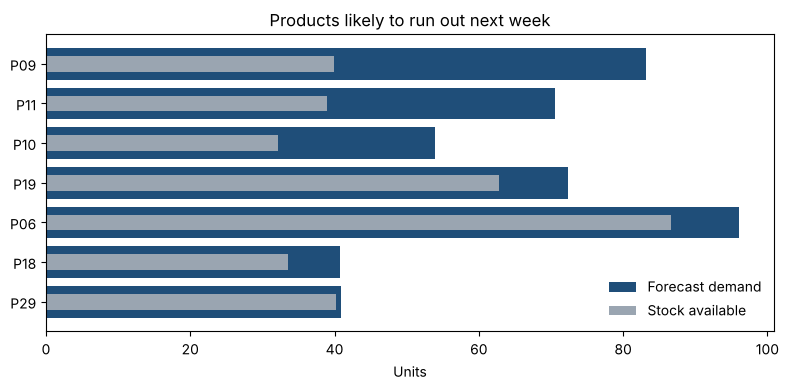

In [21]:
at_risk = table[table.at_risk].sort_values("expected_short")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(at_risk.product_id, at_risk.forecast, color="#1f4e79", label="Forecast demand")
ax.barh(at_risk.product_id, at_risk.on_hand + at_risk.on_order, color="#9aa5b1", height=0.4, label="Stock available")
ax.set_xlabel("Units")
ax.set_title("Products likely to run out next week")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/figures/05_at_risk.png", dpi=150)
plt.show()

In [22]:
per_product = pd.DataFrame({
    "product_id": test.product_id,
    "abs_error": (test.target - predict(BEST, test, final_models)).abs(),
    "actual": test.target,
}).groupby("product_id").sum()
per_product["error_rate"] = (per_product.abs_error / per_product.actual).round(3)
per_product = per_product.sort_values("error_rate", ascending=False)[["error_rate"]]
per_product.to_csv("outputs/hardest_to_forecast.csv")
per_product.head(5)

,error_rate
product_id,
P16,0.492
P12,0.462
P02,0.393
P09,0.371
P07,0.367


## 9. Saved files

Everything the notebook created is listed below.

In [23]:
saved = sorted(os.path.join(r, f) for r, _, fs in os.walk("outputs") for f in fs)
saved.append("data/sales_clean.csv")
pd.Series(saved, name="saved_files")

0                              outputs/accuracy.csv
1                      outputs/business_report.docx
2                         outputs/feature_table.csv
3               outputs/figures/01_weekly_total.png
4                outputs/figures/02_seasonality.png
5                   outputs/figures/03_accuracy.png
6            outputs/figures/04_cost_comparison.png
7                    outputs/figures/05_at_risk.png
8                    outputs/forecast_next_week.csv
9                   outputs/hardest_to_forecast.csv
10                       outputs/next_week_plan.csv
11                  outputs/presentation_guide.docx
12                           outputs/promo_lift.csv
13                   outputs/reorder_cost_95pct.csv
14                 outputs/reorder_cost_optimal.csv
15    outputs/reorder_recommendations_next_week.csv
16                 outputs/seasonality_by_month.csv
17                       outputs/tuning_results.csv
18                outputs/validation_comparison.csv
19          